# Local Import Requirements

In [1]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


In [2]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern

import gc
import pickle
import time

2026-04-02 13:51:41.689266: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
# import inspect
# import sionna.rt.path_solvers.sb_candidate_generator as sb
# print(inspect.getfile(sb))

In [5]:
print(tf.config.list_physical_devices())
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Helper Functions

In [6]:
def mean_and_variance(taus, amps):
    tau_m = []
    tau_rms = []

    for i, t in enumerate(taus):
        t = np.asarray(t)
        a = np.asarray(amps[i])

        idx = np.argsort(t)
        t = t[idx]
        a = a[idx]

        tau0 = t[0]

        P = np.abs(a)**2          # power weights
        den = np.sum(P)

        dt = t - tau0
        
        m = np.dot(dt, P) / den
        v = np.dot((dt - m)**2, P) / den

        tau_m.append(m)
        tau_rms.append(np.sqrt(v))

    return tau_m, tau_rms

In [7]:
def calculate_path_distance(tx_pos, rx_pos, points, objects):
    """
    returns distance for path, number of bounces
    """
    # Calculate distances between consecutive vertices
    segment_distances = []
    total_distance = 0.0
    depth = 0
    
    total_points = []
    total_points.append(tx_pos)
    
    i = 0
    while i < 5 and not all(np.isclose([0.0, 0.0, 0.0], points[i])):
        # drop invalid points(negative z, or bad objects)
        if points[i, 2] >= 0 and objects[i] != 4294967295 :
            total_points.append(points[i])
        
        i += 1
    total_points.append(rx_pos)
    # print(total_points)
    total_points = np.asarray(total_points)
        
    for j in range(len(total_points) - 1):
        segment_dist = np.linalg.norm(total_points[j+1, :] - total_points[j, :])
        segment_distances.append(segment_dist)
        total_distance += segment_dist
        depth += 1

    # print("Total path distance:", total_distance)    
    depth = depth - 1
    return total_distance, depth

In [ ]:
# Borrowed from Sionna report

# Calculate angle between two vectors
def angle_between_vectors(v1, v2):
    """Calculate the angle in degrees between two vectors."""
    v1_u = v1 / np.linalg.norm(v1)
    v2_u = v2 / np.linalg.norm(v2)
    dot_product = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    # print("Dot product:", dot_product)
    angle_rad = np.arccos(dot_product)
    # print("Angle in radians:", angle_rad)
    angle_deg = np.degrees(angle_rad)
    # print("Angle in degrees:", angle_deg)
    return angle_deg

# Calculate Fresnel reflection coefficient
def fresnel_reflection_coefficient(epsilon_r, sigma, fc, epsilon_0, incident_angle_deg):
    """Calculate the Fresnel reflection coefficient for perpendicular polarization."""
    
    epsilon_c = epsilon_r - 1j * sigma / (2 * np.pi * fc * epsilon_0)
#     print("Hand Complex permittivity:", epsilon_c)
    incident_angle_rad = np.radians(incident_angle_deg)

    Z = np.sqrt(epsilon_c-np.cos(incident_angle_rad)**2)
    R_parallel = (epsilon_c*np.sin(incident_angle_rad) - Z) / (epsilon_c*np.sin(incident_angle_rad) + Z)
    R_perpendicular = (np.sin(incident_angle_rad) - Z) / (np.sin(incident_angle_rad) + Z)
    # R = np.sqrt((np.abs(R_parallel)**2 + np.abs(R_perpendicular)**2) / 2)

    return R_perpendicular, R_parallel

# Convert reflection coefficient to normalized reflection loss in dB
def normalized_reflection_loss(G_t, G_r, R, d, fc):
    """Convert reflection coefficient to normalized reflection loss in dB."""

    c = 3e8  # Speed of light in m/s
    wavelength = c / fc
    RL = (G_t * G_r * (np.abs(R)**2)  * wavelength**2) / ((4 * np.pi * d)**2)
    RL_dB = -10 * np.log10(RL)
    
    return RL_dB

def normalized_scattered_reflection_loss(
    G_t, G_r, R_par, R_perp, fc,
    tx_pos, ground_bounce_point, rx_pos,
    beam_angle, n_rays=1_000_000
):
    """
    Compute diffuse-scatter path power gain using the full Jones matrix
    polarisation formulation for a ground-bounce event.

    The TX->scatter leg distance (d1) cancels exactly with the illuminated
    area element, so only d2 (scatter->RX) appears in the Friis factor.

    Parameters
    ----------
    G_t, G_r            : TX / RX antenna gains (linear)
    R_par               : Fresnel TM (p / parallel) reflection coefficient (complex)
    R_perp              : Fresnel TE (s / perpendicular) reflection coefficient (complex)
    fc                  : carrier frequency (Hz)
    tx_pos              : (3,) transmitter position (m)
    ground_bounce_point : (3,) scatter point on ground (m)
    rx_pos              : (3,) receiver position (m)
    beam_angle          : half-cone angle of TX beam (rad); set to
                          np.arccos(1 - 2/(4*np.pi / delta_omega_iso))
                          for isotropic, or np.arctan(scene_radius / d1)
                          for cone beamforming
    n_rays              : number of rays in the launch (sets ΔΩ = Ω_cone / n_rays)

    Returns
    -------
    RL_dB   : path loss in dB (positive = loss)
    """
    s = 0.4          # scattering parameter
    c = 3e8
    wavelength = c / fc

    tx = np.asarray(tx_pos,              dtype=float).ravel()
    bp = np.asarray(ground_bounce_point, dtype=float).ravel()
    rx = np.asarray(rx_pos,              dtype=float).ravel()

    # ── Surface normal: upward for ground bounce ─────────────────────────────
    n_hat = np.array([0., 0., 1.])

    # ── Ray directions ───────────────────────────────────────────────────────
    inc_vec  = bp - tx      # TX  →  scatter point
    scat_vec = rx - bp      # scatter point  →  RX

    d1 = np.linalg.norm(inc_vec)
    d2 = np.linalg.norm(scat_vec)

    k_i = inc_vec  / d1     # unit incident direction  (toward surface)
    k_s = scat_vec / d2     # unit scattered direction (away from surface)

    # ── TE / TM polarisation frames ──────────────────────────────────────────
    def te_tm_frame(k_hat, n_hat):
        """
        Returns (s_hat, p_hat) — the TE and TM basis vectors for a ray with
        direction k_hat at a surface with outward normal n_hat.

          s_hat : TE  — perpendicular to the plane of incidence (= k × n̂)
          p_hat : TM  — in the plane of incidence, perpendicular to k_hat
                        (= s_hat × k_hat, so (s, p, k) is right-handed)
        """
        cross = np.cross(k_hat, n_hat)
        norm  = np.linalg.norm(cross)

        s_hat = cross / norm
        p_hat = np.cross(s_hat, k_hat)   # TM: in plane of incidence, ⊥ to k
        return s_hat, p_hat

    s_i, p_i = te_tm_frame(k_i, n_hat)   # incident  TE/TM frame
    s_s, p_s = te_tm_frame(k_s, n_hat)   # scattered TE/TM frame

    # ── Change-of-basis matrix M ─────────────────────────────────────────────
    # Rotates from the incident TE/TM frame into the scattered TE/TM frame.
    # Each entry is the dot product of the corresponding basis vectors:
    #
    #   M = | s_s·s_i   s_s·p_i |
    #       | p_s·s_i   p_s·p_i |
    #
    M = np.array([
        [np.dot(s_s, s_i), np.dot(s_s, p_i)],
        [np.dot(p_s, s_i), np.dot(p_s, p_i)]
    ])  # (2, 2) real

    
    # Unpolarised: average TE and TM contributions weighted by row norms of M.
    # Equivalent to averaging over all input polarisations and summing outputs.
    #   = (|Γ_⊥|² · ||row1(M)||² + |Γ_∥|² · ||row2(M)||²) / 2
    row1_norm_sq = np.dot(M[0], M[0])   # ||ŝ_s projected onto incident frame||²
    row2_norm_sq = np.dot(M[1], M[1])   # ||p̂_s projected onto incident frame||²

    gamma_eff_sq = (np.abs(R_perp)**2 * row1_norm_sq + np.abs(R_par )**2 * row2_norm_sq) / 2



    # ── Lambertian angular factor ─────────────────────────────────────────────
    # cos θ_s : angle between the scattered ray and the surface normal.
    cos_theta_s = np.abs(np.dot(k_s, n_hat))

    # ── Per-ray solid angle ───────────────────────────────────────────────────
    # Total solid angle of the launch cone divided by number of rays.
    omega_cone  = 2 * np.pi * (1 - np.cos(beam_angle))
    delta_omega = omega_cone / n_rays

    # ── Diffuse sampling probability ──────────────────────────────────────────
    p_diff = 1

    # ── Scattered path power gain ─────────────────────────────────────────────
    #
    #   |h|² = G_t · G_r · (1/p_diff) · ΔΩ · S² · |Γ_eff|² · (cosθ_s/π) · (λ/4πd₂)²
    #
    # Key corrections vs original:
    #   • |Γ_eff|²  replaces scalar |R|²  (full polarisation coupling)
    #   • d2 only   replaces total d       (d1 cancels with area element)
    #   • (λ/4πd₂)² Friis factor uses d2
    power_gain = (
        G_t * G_r
        * (1.0 / p_diff)
        * delta_omega
        * s**2
        * gamma_eff_sq
        * (cos_theta_s / np.pi)
        * (wavelength / (4.0 * np.pi * d2))**2
    )

    RL_dB = -10.0 * np.log10(power_gain)
    return RL_dB


In [9]:
friis = lambda d, f: 20*np.log10(d) + 20*np.log10(f) - 147.55

# Two Ray Rician Testbench

In [10]:
rx_pos = [0,0,0.5]
tx_pos = [100, 0, 10]

angle = np.arctan(50/np.linalg.norm(tx_pos))

In [11]:
from scipy.special import i0e

def rician_pdf(x, K, Omega):
    x = np.asarray(x, dtype=np.float64)
    x_safe = np.maximum(x, 1e-300)

    z = 2 * x_safe * np.sqrt(K * (K + 1) / Omega)

    log_pdf = (
        np.log(2 * x_safe * (K + 1) / Omega)
        - K
        - ((K + 1) * x_safe**2) / Omega
        + z
        + np.log(i0e(z))
    )
    return np.exp(log_pdf)
    

In [12]:
def get_complex_channel(taus, amps, f=11.7e9):
    a = np.array(amps, dtype=complex)
    t = np.array(taus, dtype=complex)
    return a*np.exp(-1j*2*np.pi*f*t)


def get_power(taus, amplitudes, interactions):
    
    LoS_idx = 0
    
    for i in range(interactions.shape[0]):
        # check for diffuse or diffract reflection and append if none
        if (np.where(interactions[i] == 2))[0].size == 0 and (np.where(interactions[i] == 8))[0].size == 0:
            # get LoS path
            LoS_idx = i
    channel = get_complex_channel(taus, amplitudes)
    P_los = np.abs(channel[LoS_idx])**2
    P_diff = np.abs(np.sum(channel[0:LoS_idx]) + np.sum(channel[LoS_idx + 1:]))**2
    
    return P_los, P_diff
    

In [38]:
# batch 1
with open("./ricain_bench.pkl", "rb") as f:
    d = pickle.load(f)
Hs_0, powers_0 = d["H"], d["powers"]

# batch 2
with open("./rician_bench_2.pkl", "rb") as f:
    d = pickle.load(f)
Hs_1, powers_1 = d["H"], d["powers"]

In [39]:
N = 10_000

S = [0.3, 0.7, 1]

f = 11.7e9

In [ ]:
start_time = time.perf_counter()

# taus = []
# amps = []
powers = []
Hs = []

means = []
variances = []

for s in S:
#     temp_tau = []
#     temp_amp = []
    temp_power = []
    h_ = []
    mu = 0
    var = 0
    for i in range(N):
        lambda_c = 3e8 / f

        # small local area (~few wavelengths)
        d = lambda_c * 2

        rx_pos = [0 + np.random.uniform(-d, d),
                  0 + np.random.uniform(-d, d),
                  0.5]

        # Set concrete scattering properties
        scene = load_scene("./flat_plane/plain.xml", merge_shapes=False)
        scene.frequency = f  # 11.7 GHz (Ku-band downlink)
        mat = scene.get("itu_concrete")
        mat.scattering_coefficient = s
        mat.scattering_pattern = LambertianPattern()
        
#         a = 5.24 + np.random.uniform(-4, 4)
#         b = 0.
#         c = 0.0462 + np.random.uniform(-0.04, 0.06)
#         d = 0.7822 + np.random.uniform(-0.78, 0.5)
#         sionna.rt.radio_materials.itu.ITU_MATERIALS_PROPERTIES["concrete"] = {
#         (1.0, 100.0): (a, b, c, d)  # (a, b, c, d) where εr=a*f^b, σ=c*f^d
#         }

        # Create Transmitter Array
        scene.tx_array = PlanarArray(
            num_rows=1, # of rows
            num_cols=1, # of columns
            vertical_spacing=0.5, # in wavelengths
            horizontal_spacing=0.5, # in wavelengths
            pattern="iso", # Antenna pattern
            polarization="V" # Vertical polarization
            )

        # Create Receiver Array
        scene.rx_array = PlanarArray(
            num_cols=1, 
            num_rows=1,
            vertical_spacing=0.5,
            horizontal_spacing=0.5,
            pattern="iso",
            polarization="V")

        tx = Transmitter(
            name="tx_1",
            position=tx_pos
        )
        scene.add(tx)

        tx.power_dbm = 43 # Transmit power in dBm

        rx = Receiver(
                name=f"ue_1",
                position= rx_pos,
                orientation=[0.0, 0.0, 0.0])
        scene.add(rx)  

        tx.look_at(rx_pos)  # Pointing to the center of the scene

    #     # Maximize number of samples
    #     num_samples = (2**32 - 1)//64 # 2^24 -1


        # Flush memory, 
        # was having problems with allocation on repeated runs
        for name in ["paths", "amp", "tau", "paths_buffer"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        drjit.flush_malloc_cache()
        drjit.eval()

        p_solver  = PathSolver()

        # Compute propagation paths
        seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
        paths = p_solver(scene=scene,
                            max_depth=1,
                            los=True,
                            specular_reflection=False,
                            diffuse_reflection=True,
                            refraction=False,
                            diffraction=False,
                            synthetic_array=False,
                            max_num_paths_per_src=1_000_000,
                            samples_per_src=1_000_000,
                            seed=seed,
                            beamforming=True,
                            beam_angle=angle)

        amp, tau = paths.cir(normalize_delays=False, out_type="numpy")


        t = tau[0,0,0,0,:] #in seconds
        amp = np.abs(amp)[0,0,0,0,:,0]
        interactions = paths.interactions.numpy()
        interactions = interactions[0,0,0,0,0,:]

    #         vertices = paths.vertices.numpy()
    #         objects = paths.objects.numpy()

        # Shape: [max_depth, num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, 3]
        # Extract vertices for specific path
    #         vertices = vertices[:, 0, 0, 0, 0, :, :]
    #         objects = objects[:,0,0,0,:,:]

        P_los, P_diff = get_power(t,amp, interactions)
        channel = get_complex_channel(t, amp)
        h_mag = np.abs(np.sum(channel))
        h_.append(h_mag)    
#         temp_tau.append(t)
#         temp_amp.append(amp)
        temp_power.append((P_los, P_diff))
        
        t_m, t_rms = mean_and_variance([t], [amp])
        mu = (mu + t_m[0])/(i+1)
        var = (var + t_rms[0])/(i+1)

    powers.append(temp_power)
    Hs.append(h_)
    means.append(mu)
    variances.append(var)

#     taus.append(temp_tau)
#     amps.append(temp_amp)

    # export path information
with open("rician_bench_3.pkl", "wb") as f:
    pickle.dump({"H": Hs, 
                 "powers": powers}, f, protocol=pickle.HIGHEST_PROTOCOL)

end_time = time.perf_counter()

/tmp/ipykernel_891773/370346949.py:13: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  if (np.where(interactions[i] == 2))[0].size == 0 and (np.where(interactions[i] == 8))[0].size == 0:


In [31]:
print(end_time - start_time)
print(len(Hs_past[0]))

75433.15768867731
10000


In [33]:
# Get K and Omega estimates
Ks = []
Omegas = []
for i in range(len(S)):
    p_los = 0
    p_diff = 0
    for j in range(N):

        p_los += powers[i][j][0]
        p_diff += powers[i][j][1]
        
        p_los += powers_past[i][j][0]
        p_diff += powers_past[i][j][1]
    
    p_los = p_los/(2*N)
    p_diff = p_diff/(2*N)
    
    K = p_los/p_diff
    Omega = p_los + p_diff
    Ks.append(K)
    Omegas.append(Omega)
        

In [34]:
print(Ks)
print(Omegas)

[3433.6037981979175, 627.8281548021209, 307.22378787841154]
[4.12167989309892e-10, 4.1270455016404107e-10, 4.1339068935833064e-10]


In [20]:
print(powers[2][6])

(4.119894933398517e-10, 6.000750765055588e-13)


In [35]:
# Generate pdf
x = []
rician = []

for i in range(len(S)):
    x_ = np.linspace(0, 2*np.max(Hs[i]), 10_000)
    x.append(x_)

    rician.append(rician_pdf(x_, Ks[i], Omegas[i]))

In [22]:
print(np.min(Hs), np.max(Hs))

1.9601026743916232e-05 2.1607012881542318e-05


Text(0.5, 0, 'x')

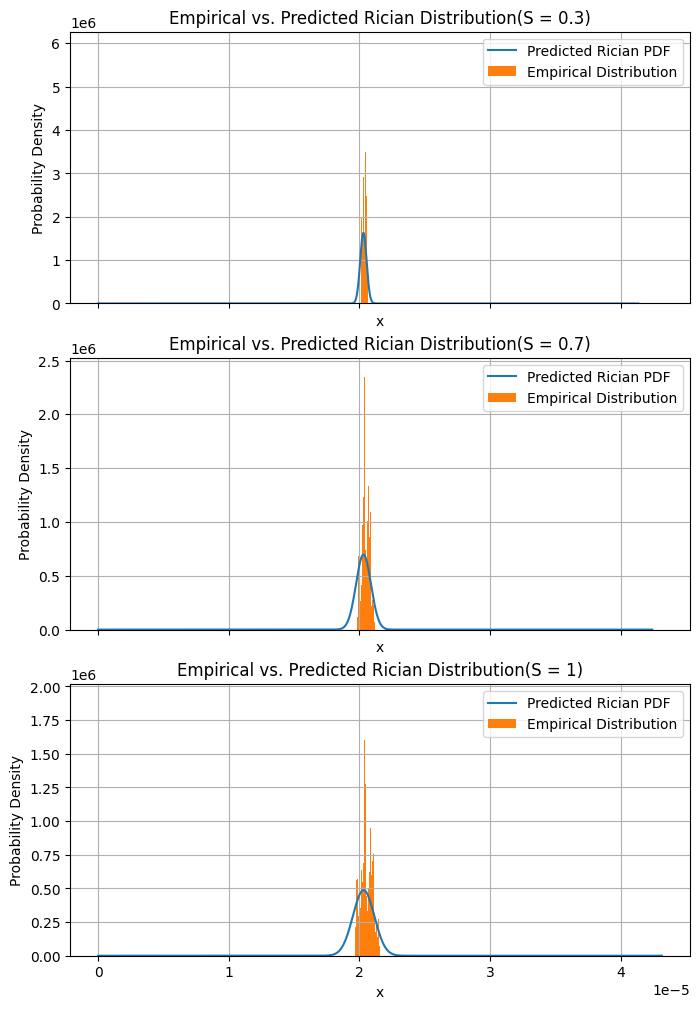

In [36]:
# Plot binned empircal rician pdf vs. predicted for S
num_bins = int(np.sqrt(2*N))

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(8, 12),
    sharex=True
)

plt.subplot(3,1,1)

plt.plot(x[0], rician[0], label="Predicted Rician PDF")
plt.hist(Hs[0],bins=num_bins, density=True, label="Empirical Distribution")

plt.title(f"Empirical vs. Predicted Rician Distribution(S = 0.3)")
plt.grid()
plt.legend()
plt.ylabel(r"Probability Density")
plt.xlabel(r"x")

plt.subplot(3,1,2)

plt.plot(x[1], rician[1], label="Predicted Rician PDF")
plt.hist(Hs[1],bins=num_bins, density=True, label="Empirical Distribution")

plt.title(f"Empirical vs. Predicted Rician Distribution(S = 0.7)")
plt.grid()
plt.legend()
plt.ylabel(r"Probability Density")
plt.xlabel(r"x")


plt.subplot(3,1,3)

plt.plot(x[2], rician[2], label="Predicted Rician PDF")
plt.hist(Hs[2],bins=num_bins, density=True, label="Empirical Distribution")

plt.title(f"Empirical vs. Predicted Rician Distribution(S = 1)")
plt.grid()
plt.legend()
plt.ylabel(r"Probability Density")
plt.xlabel(r"x")

In [136]:
# Bin CIR realizations to generate aggregated synthetic CIR
time_delays = []
complex_coeffs = []

for i in range(len(S)):
    ti = np.array([])
    ai = np.array([], dtype=complex)
    
    for j in range(N):
        ti = np.concatenate((ti, np.asarray(taus[i][j])))
        ai = np.concatenate((ai, np.asarray(amps[i][j], dtype=complex)))
    
    idx = np.argsort(ti)
    ti = ti[idx]
    ai = ai[idx]
    
    time_delays.append(ti)
    complex_coeffs.append(ai)

KeyboardInterrupt: 

In [141]:
# Calculate Mean and Variance

means = []
variances = []
for i in range(len(S)):
    tau_m, tau_rms = mean_and_variance(taus[i], amps[i])
    
    means.append(np.mean(tau_m))
    variances.append(np.mean(tau_rms))
        

print(means)
print(variances)

[8.422281e-10, 2.5494546e-09, 4.491884e-09]
[7.825785e-09, 1.3454858e-08, 1.7613456e-08]


In [710]:
# Get dB amplitude

db_250 = [20*np.log10(i) for i in sionna_amps_250]

# Sorted weakest to strongest paths
idx_20 = np.argsort(db_250[0])
idx_50 = np.argsort(db_250[1])
idx_90 = np.argsort(db_250[2])
# print(db_250[0][non_diff_idx[0]])

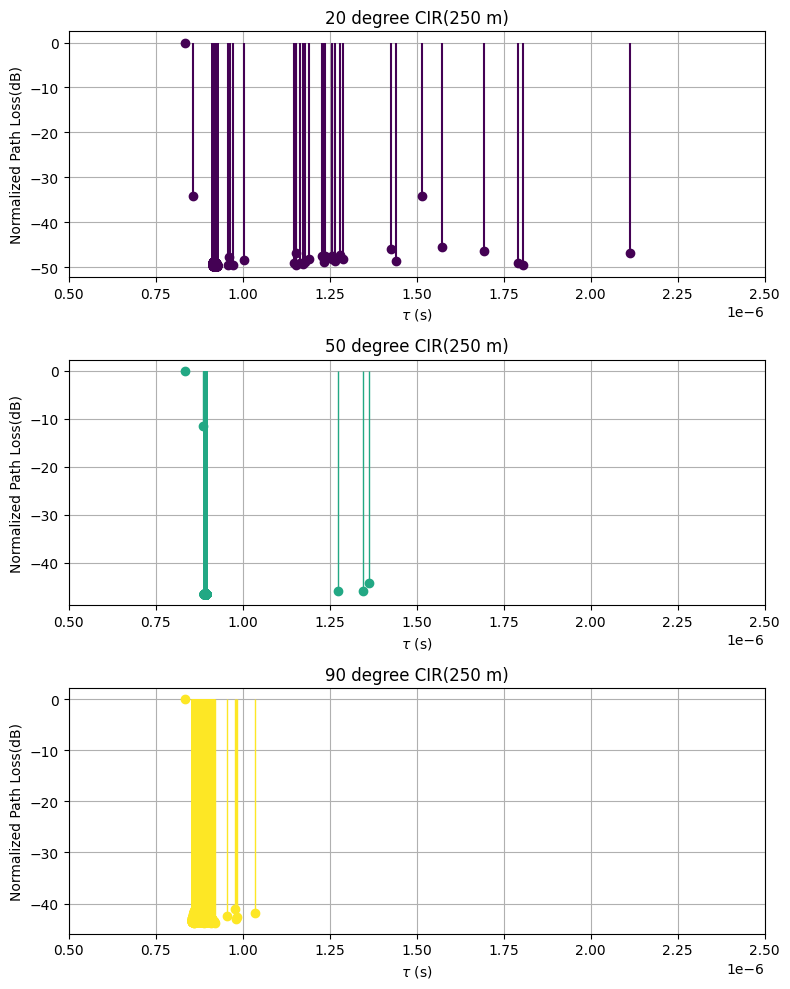

In [715]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(8, 10)
)

cmap = mpl.colormaps['viridis']
C = cmap(np.linspace(0, 1, 6))

plt.subplot(3,1,1)


markerline, stemlines, baseline = plt.stem(sionna_taus_250[0][idx_20[-1000:]], 
                                           db_250[0][idx_20[-1000:]]-np.max(db_250[0])
                                           ,basefmt=" ")


plt.setp(markerline, color=C[0], markersize=6)
plt.setp(stemlines, color=C[0], linewidth=1.5)
plt.title(f"20 degree CIR(250 m)")
plt.grid()
plt.ylabel(r"Normalized Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
plt.xlim(0.5e-6, 2.5e-6)

plt.subplot(3,1,2)
markerline, stemlines, baseline = plt.stem(sionna_taus_250[1][idx_50[-1000:]], 
                                           db_250[1][idx_50[-1000:]]-np.max(db_250[1]),
                                           basefmt=" ",)


plt.setp(markerline, color=C[3], markersize=6)
plt.setp(stemlines, color=C[3], linewidth=1.0)

plt.title(f"50 degree CIR(250 m)")
plt.grid()
plt.ylabel(r"Normalized Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
plt.xlim(0.5e-6, 2.5e-6)

plt.subplot(3,1,3)

markerline, stemlines, baseline = plt.stem(sionna_taus_250[2][idx_90[-1000:]], 
                                           db_250[2][idx_90[-1000:]]-np.max(db_250[2])
                                           ,basefmt=" ")


plt.setp(markerline, color=C[5], markersize=6)
plt.setp(stemlines, color=C[5], linewidth=1.0)
# Color configuration
plt.title(f"90 degree CIR(250 m)")
plt.grid()
plt.ylabel(r"Normalized Path Loss(dB)")
plt.xlabel(r"$\tau$ (s)")
plt.xlim(0.5e-6, 2.5e-6)

# plt.xlim(800, 1200)

# plt.legend()
plt.tight_layout()
plt.show()

# Generate Visual

In [122]:
lambda_c = 3e8 / f

# small local area (~few wavelengths)
d = lambda_c * 2

rx_pos = [0 + np.random.uniform(-d, d),
          0 + np.random.uniform(-d, d),
          0.5]

# Set concrete scattering properties
scene = load_scene("./flat_plane/plain.xml", merge_shapes=False)
scene.frequency = f  # 11.7 GHz (Ku-band downlink)
mat = scene.get("itu_concrete")
mat.scattering_coefficient = 0.6
mat.scattering_pattern = LambertianPattern()

# Create Transmitter Array
scene.tx_array = PlanarArray(
    num_rows=1, # of rows
    num_cols=1, # of columns
    vertical_spacing=0.5, # in wavelengths
    horizontal_spacing=0.5, # in wavelengths
    pattern="iso", # Antenna pattern
    polarization="V" # Vertical polarization
    )

# Create Receiver Array
scene.rx_array = PlanarArray(
    num_cols=1, 
    num_rows=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V")

tx = Transmitter(
    name="tx_1",
    position=tx_pos
)
scene.add(tx)

tx.power_dbm = 43 # Transmit power in dBm

rx = Receiver(
        name=f"ue_1",
        position= rx_pos,
        orientation=[0.0, 0.0, 0.0])
scene.add(rx)  

tx.look_at(rx_pos)  # Pointing to the center of the scene



p_solver  = PathSolver()

# Compute propagation paths
seed = drjit.cuda.ad.UInt(np.random.randint(1,100000))
paths = p_solver(scene=scene,
                    max_depth=1,
                    los=True,
                    specular_reflection=False,
                    diffuse_reflection=True,
                    refraction=False,
                    diffraction=False,
                    synthetic_array=False,
                    max_num_paths_per_src=100,
                    samples_per_src=10_000,
                    seed=seed,
                    beamforming=True,
                    beam_angle=angle)

a_vis, t_vis = paths.cir(normalize_delays=False, out_type="numpy")

In [130]:
bird_cam = Camera(position=[-100,-140,200], look_at=rx_pos)
scene.render_to_file(camera=bird_cam, filename="./rician_vis.png", paths=paths)

2026-03-20 13:54:44 WARN  [integrator_v.cpp:38] Received interrupt signal, winding down..


RuntimeError: drjit.custom(<mitsuba.python.util._RenderOp>): error while performing a custom differentiable operation. (see above).